<a href="https://colab.research.google.com/github/CarlosJB95/PathIA-MSI-colon/blob/main/Notebook_07_embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Notebook 07 — Embeddings**
### Día 41 · 16-nov-2026

---
*Material de aprendizaje — sin uso clínico.*


### **§0 Setup y descargas**

---

Qué hace: fija la semilla, monta Drive, verifica las cachés del Mes 2 y descarga una sola vez los pesos de ResNet-50 a Downloads/hf_models/. Después de esta celda nada vuelve a tocar internet.
Puente: pedir el material al archivo antes de sentarte al microscopio.

In [15]:
# §0 Setup y descargas — lo único que usa internet hoy
import os, random
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

from google.colab import drive
drive.mount("/content/drive")
assert os.path.ismount("/content/drive"), "Drive NO está montado: no continúes"

from pathlib import Path
PROYECTO  = Path("/content/drive/MyDrive/DigiPath/IA Docs/PathIA 3.0")
DOWNLOADS = PROYECTO / "Downloads"
RESULTS   = PROYECTO / "results"
CACHE_NCT = DOWNLOADS / "nct_dia24.npz"
CACHE_TEX = DOWNLOADS / "nct_textura_d1-3_n32.npz"
assert CACHE_NCT.exists() and CACHE_TEX.exists(), "Faltan las cachés del Mes 2 en Downloads/"
RESULTS.mkdir(parents=True, exist_ok=True)

!pip -q install timm          # Colab suele traerlo; esto solo lo asegura

import torch, timm
torch.manual_seed(SEED)
print("torch", torch.__version__, "| timm", timm.__version__, "| GPU:", torch.cuda.is_available())

from huggingface_hub import snapshot_download
DIR_PESOS = DOWNLOADS / "hf_models" / "resnet50.a1_in1k"
snapshot_download("timm/resnet50.a1_in1k", local_dir=DIR_PESOS,
                  allow_patterns=["model.safetensors", "config.json"])
ARCHIVO_PESOS = DIR_PESOS / "model.safetensors"
print("Pesos:", ARCHIVO_PESOS, f"· {ARCHIVO_PESOS.stat().st_size / 1e6:.1f} MB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
torch 2.14.1+cu130 | timm 1.0.31 | GPU: True


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Pesos: /content/drive/MyDrive/DigiPath/IA Docs/PathIA 3.0/Downloads/hf_models/resnet50.a1_in1k/model.safetensors · 102.5 MB


### **§1 Un lote de 8 parches (solo train)**

---

Qué hace: carga las imágenes desde la caché y elige 4 TUM y 4 NORM de train con semilla 42. El test no se abre hoy.
Puente: seleccionar campos representativos de dos casos conocidos antes de comparar.

TRAIN (1200, 224, 224, 3) uint8 {'TUM': 600, 'NORM': 600}


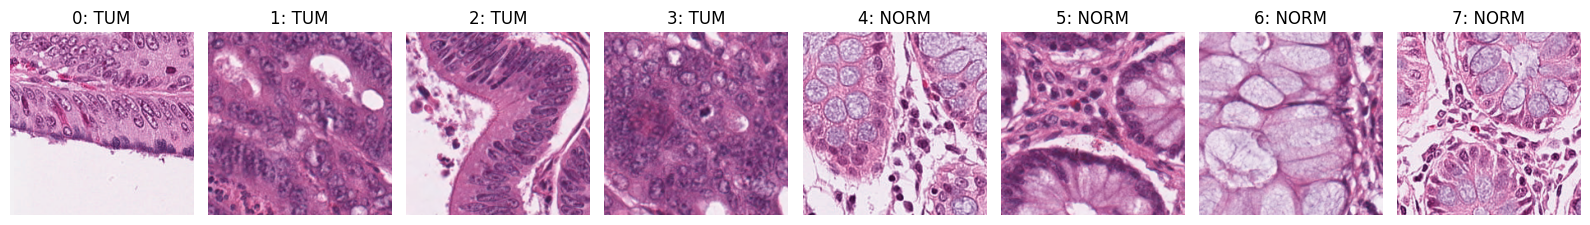

In [16]:
d = np.load(CACHE_NCT)
Xtr, ytr = d["Xtr"], d["ytr"]                 # solo TRAIN
print("TRAIN", Xtr.shape, Xtr.dtype, {c: int((ytr == c).sum()) for c in ["TUM", "NORM"]})

rng = np.random.default_rng(SEED)
idx_tum  = rng.choice(np.where(ytr == "TUM")[0],  size=4, replace=False)
idx_norm = rng.choice(np.where(ytr == "NORM")[0], size=4, replace=False)
idx_lote  = np.concatenate([idx_tum, idx_norm])   # posiciones 0–3 TUM, 4–7 NORM
etiquetas = ytr[idx_lote]

import matplotlib.pyplot as plt
fig, ejes = plt.subplots(1, 8, figsize=(16, 2.6))
for k, (eje, i) in enumerate(zip(ejes, idx_lote)):
    eje.imshow(Xtr[i]); eje.set_title(f"{k}: {ytr[i]}"); eje.axis("off")
plt.tight_layout(); plt.show()

### **§2 ResNet-50 sin cabeza = extractor de rasgos**

---

Qué hace: carga ResNet-50 desde el archivo local, sin la capa final de 1000 clases de ImageNet (num_classes=0), en modo evaluación.
Puente: usar al observador experto solo para describir, no para dar su diagnóstico de «perro» o «coche».

In [17]:
modelo = timm.create_model(
    "resnet50.a1_in1k", pretrained=True, num_classes=0,
    pretrained_cfg_overlay=dict(file=str(ARCHIVO_PESOS)),   # offline: desde la caché
)
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
modelo = modelo.to(dispositivo).eval()
print(f"Parámetros: {sum(p.numel() for p in modelo.parameters()) / 1e6:.1f} M"
      f" | rasgos por parche: {modelo.num_features}")

Parámetros: 23.5 M | rasgos por parche: 2048


### **§6.0 Determinismo de la GPU**
Qué hace: pide a la GPU que use siempre los mismos algoritmos de convolución, para que el mismo parche dé siempre el mismo vector. Puente: fijar el programa del teñidor para que dos corridas del mismo bloque salgan iguales.

In [18]:
# §6.0 Determinismo: mismos algoritmos de convolución en cada corrida
import copy
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print("Modelo en modo entrenamiento:", modelo.training)   # debe decir False (eval)

Modelo en modo entrenamiento: False


### **§3 Embeddings del lote**

---

Qué hace: aplica el preprocesamiento de timm (caja negra hoy; se abre el Día 42), apila los 8 parches en un tensor y obtiene un vector por parche sin calcular gradientes.
Predicción antes de correr: forma del lote = ¿? · forma de la salida = ¿? · ¿habrá valores negativos?
Puente: de la imagen al informe sinóptico, pero con 2048 casillas que nadie nombró.

In [19]:
from PIL import Image

cfg = timm.data.resolve_data_config({}, model=modelo)
transform = timm.data.create_transform(**cfg)
print(cfg)                                     # fíjate en mean, std y crop_pct

lote = torch.stack([transform(Image.fromarray(Xtr[i])) for i in idx_lote]).to(dispositivo)
print("Lote de entrada:", tuple(lote.shape))

with torch.no_grad():
    emb = modelo(lote).cpu().numpy()
print("Embeddings:", emb.shape,
      f"| mínimo {emb.min():.3f} | máximo {emb.max():.3f} | % ceros {(emb == 0).mean():.1%}")

{'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'crop_pct': 0.95, 'crop_mode': 'center'}
Lote de entrada: (8, 3, 224, 224)
Embeddings: (8, 2048) | mínimo 0.000 | máximo 2.684 | % ceros 42.6%


### **§4 ¿Qué parches «le parecen» iguales al modelo?**

---

Qué hace: normaliza cada vector a longitud 1 y calcula la similitud coseno entre todos los pares (8 × 8). Resume TUM–TUM, NORM–NORM y TUM–NORM.
Predicción: ¿qué es mayor, TUM–TUM o TUM–NORM?
Puente: comparar dos campos y decidir si son el mismo tejido.

ResNet-50 (2048)       TUM–TUM 0.543 | NORM–NORM 0.645 | TUM–NORM 0.551


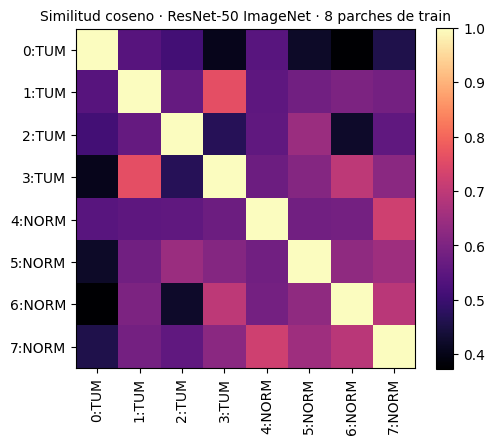

In [20]:
def matriz_coseno(F):
    """Similitud coseno entre las filas de F (n, p) → matriz (n, n)."""
    Fn = F / np.linalg.norm(F, axis=1, keepdims=True)
    return Fn @ Fn.T

def resumen_coseno(S, titulo):
    iu = np.triu_indices(4, k=1)                   # pares distintos dentro de cada clase
    print(f"{titulo:<22} TUM–TUM {S[:4, :4][iu].mean():.3f} | "
          f"NORM–NORM {S[4:, 4:][iu].mean():.3f} | TUM–NORM {S[:4, 4:].mean():.3f}")

def figura_coseno(S, titulo, archivo):
    nombres = [f"{k}:{e}" for k, e in enumerate(etiquetas)]
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    im = ax.imshow(S, cmap="magma"); plt.colorbar(im)
    ax.set_xticks(range(8), nombres, rotation=90); ax.set_yticks(range(8), nombres)
    ax.set_title(titulo, fontsize=10)
    plt.tight_layout(); plt.savefig(RESULTS / archivo, dpi=150); plt.show()

S_resnet = matriz_coseno(emb)
resumen_coseno(S_resnet, "ResNet-50 (2048)")
figura_coseno(S_resnet, "Similitud coseno · ResNet-50 ImageNet · 8 parches de train",
              "07_coseno_resnet50_lote8.png")

### **§5 Variante: la misma pregunta con los rasgos que tú elegiste**

---

Qué hace: recalcula las 6 features de color, añade las 5 de textura desde la caché, estandariza (escalador ajustado en train) y repite la matriz coseno.
Puente: la misma comparación con tu hoja de criterios en lugar del golpe de vista.

Features hechas a mano: (1200, 11)
Color + textura (11)   TUM–TUM 0.069 | NORM–NORM -0.090 | TUM–NORM -0.168
ResNet-50 (2048)       TUM–TUM 0.543 | NORM–NORM 0.645 | TUM–NORM 0.551


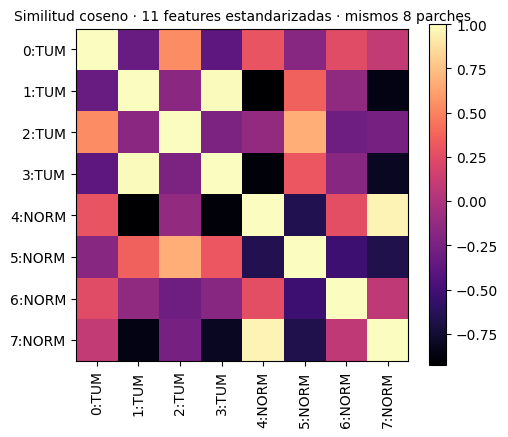

In [21]:
from sklearn.preprocessing import StandardScaler

def features_color(tile_rgb):
    """Media y DE por canal de un parche RGB (alto, ancho, 3) → vector (6,)."""
    return np.concatenate([tile_rgb.mean(axis=(0, 1)), tile_rgb.std(axis=(0, 1))])

Xtr_color = np.stack([features_color(t) for t in Xtr])
Xtr_tex   = np.load(CACHE_TEX)["Xtr_tex"]          # mismo orden que Xtr
X11_tr    = np.hstack([Xtr_color, Xtr_tex])
print("Features hechas a mano:", X11_tr.shape)

escala = StandardScaler().fit(X11_tr)              # ajustado en train (aquí no hay test)
S_11 = matriz_coseno(escala.transform(X11_tr[idx_lote]))
resumen_coseno(S_11, "Color + textura (11)")
resumen_coseno(S_resnet, "ResNet-50 (2048)")
figura_coseno(S_11, "Similitud coseno · 11 features estandarizadas · mismos 8 parches",
              "07_coseno_11feat_lote8.png")

In [22]:
print(np.round(S_11[:4, :4], 2))   # solo los 4 TUM: ¿0 y 2 siguen lejos de 1 y 3?

[[ 1.   -0.33  0.54 -0.38]
 [-0.33  1.   -0.17  0.99]
 [ 0.54 -0.17  1.   -0.23]
 [-0.38  0.99 -0.23  1.  ]]


### **§6 El protocolo que espera el modelo**

---
Qué hace: imprime la configuración de datos de resnet50.a1_in1k y los pasos exactos del transform de timm.
Predicción: ¿cuántos pasos tiene el transform? ¿Cuál cambia el tamaño de la imagen?
Puente: leer el inserto del anticuerpo antes de teñir.

In [23]:
from PIL import Image

cfg = timm.data.resolve_data_config({}, model=modelo)
transform = timm.data.create_transform(**cfg)
for clave in ["input_size", "interpolation", "crop_pct", "mean", "std"]:
    print(f"{clave:<14}", cfg[clave])
print(transform)

input_size     (3, 224, 224)
interpolation  bicubic
crop_pct       0.95
mean           (0.485, 0.456, 0.406)
std            (0.229, 0.224, 0.225)
Compose(
    Resize(size=235, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeToTensor()
    Normalize(mean=tensor([0.4850, 0.4560, 0.4060]), std=tensor([0.2290, 0.2240, 0.2250]))
)


### **§7 Un parche, paso a paso**

---
Qué hace: convierte un parche de train a tensor a mano (canales primero, valores de 0 a 1, normalización por canal) y lo compara con el tensor de timm. Guarda una figura con el original, lo que ve el modelo y la diferencia entre ambos.
Puente: del bloque de parafina al corte montado: mismo tejido, otro formato.

Imagen: (224, 224, 3) uint8 | mín 10 | máx 255
Tensor: (3, 224, 224) | rango 0.04–1.00
Normalizado a mano · rango -1.86 a 2.64
timm: (3, 224, 224) | diferencia máxima con el tuyo: 4.097


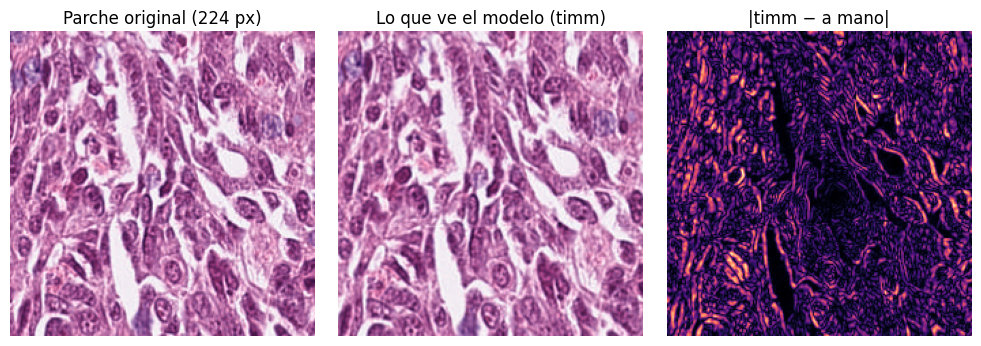

In [24]:
i0 = int(np.where(ytr == "TUM")[0][0])          # primer parche TUM de train
img = Xtr[i0]
print("Imagen:", img.shape, img.dtype, "| mín", img.min(), "| máx", img.max())

# 1) canales primero  2) a decimales entre 0 y 1
t = torch.from_numpy(img).permute(2, 0, 1).float() / 255.0
print("Tensor:", tuple(t.shape), f"| rango {t.min():.2f}–{t.max():.2f}")

# 3) normalización por canal con la media y la DE de ImageNet
MEDIA = torch.tensor(cfg["mean"]).view(3, 1, 1)
DE    = torch.tensor(cfg["std"]).view(3, 1, 1)
t_mano = (t - MEDIA) / DE
print(f"Normalizado a mano · rango {t_mano.min():.2f} a {t_mano.max():.2f}")

# 4) el transform de timm sobre el mismo parche
t_timm = transform(Image.fromarray(img))
print("timm:", tuple(t_timm.shape),
      f"| diferencia máxima con el tuyo: {(t_timm - t_mano).abs().max():.3f}")

def a_imagen(tn):
    """Deshace la normalización para poder mirar el tensor como imagen RGB."""
    return (tn * DE + MEDIA).clamp(0, 1).permute(1, 2, 0).numpy()

fig, ejes = plt.subplots(1, 3, figsize=(10, 3.4))
ejes[0].imshow(img);                ejes[0].set_title("Parche original (224 px)")
ejes[1].imshow(a_imagen(t_timm));   ejes[1].set_title("Lo que ve el modelo (timm)")
ejes[2].imshow(np.abs(a_imagen(t_timm) - a_imagen(t_mano)).mean(axis=2), cmap="magma")
ejes[2].set_title("|timm − a mano|")
for e in ejes: e.axis("off")
plt.tight_layout(); plt.savefig(RESULTS / "07_preproc_parche.png", dpi=150); plt.show()

### **§8 Extraer embeddings por lotes**

---
Qué hace: define extraer(). La función preprocesa los parches, los apila de 64 en 64, los pasa por el modelo sin calcular gradientes y junta los vectores. El Día 43 recorrerá con ella los 1800 parches.
Puente: cargar el teñidor por gradillas, no laminilla por laminilla.

In [25]:
def prep_timm(im):
    """Preprocesamiento oficial del modelo (ficha de timm)."""
    return transform(Image.fromarray(im))

def prep_mano(im):
    """Preprocesamiento a mano: sin Resize ni CenterCrop; solo tensor, /255 y normalización."""
    t = torch.from_numpy(im).permute(2, 0, 1).float() / 255.0
    return (t - MEDIA) / DE

def extraer(modelo, imgs, prep, bs=64):
    """Embeddings (n, 2048) de un arreglo de parches (n, 224, 224, 3), por lotes de bs."""
    salidas = []
    with torch.no_grad():
        for k in range(0, len(imgs), bs):
            lote = torch.stack([prep(im) for im in imgs[k:k + bs]]).to(dispositivo)
            salidas.append(modelo(lote).cpu().numpy())
    return np.concatenate(salidas)

rng = np.random.default_rng(SEED)
idx64 = np.concatenate([rng.choice(np.where(ytr == "TUM")[0],  32, replace=False),
                        rng.choice(np.where(ytr == "NORM")[0], 32, replace=False)])
imgs64, etq64 = Xtr[idx64], ytr[idx64]          # posiciones 0–31 TUM, 32–63 NORM
print("Lote:", imgs64.shape, {c: int((etq64 == c).sum()) for c in ["TUM", "NORM"]})

Lote: (64, 224, 224, 3) {'TUM': 32, 'NORM': 32}


### **§9 Reproducibilidad de la extracción**

---
Qué hace: extrae el lote de 64 dos veces en eval() y mide la diferencia. Luego extrae solo los primeros 8 en un lote de 8. La pregunta: ¿el vector de un parche depende de sus compañeros de lote?
Puente: teñir dos veces el mismo corte con el mismo programa.

In [26]:
emb_a = extraer(modelo, imgs64, prep_timm)
emb_b = extraer(modelo, imgs64, prep_timm)
emb_8 = extraer(modelo, imgs64[:8], prep_timm, bs=8)
print("Forma:", emb_a.shape)
print(f"Corrida 1 vs 2    · diferencia máxima {np.abs(emb_a - emb_b).max():.2e}"
      f" | idénticos: {np.array_equal(emb_a, emb_b)}")
print(f"Lote 64 vs lote 8 · diferencia máxima {np.abs(emb_a[:8] - emb_8).max():.2e}"
      f" | casi iguales (atol 1e-4): {np.allclose(emb_a[:8], emb_8, atol=1e-4)}")

Forma: (64, 2048)
Corrida 1 vs 2    · diferencia máxima 0.00e+00 | idénticos: True
Lote 64 vs lote 8 · diferencia máxima 3.58e-06 | casi iguales (atol 1e-4): True


### **§9.1 Qué cambia si olvidas model.eval()**

Qué hace: pone una copia del modelo en modo entrenamiento; el original no se toca. Compara los vectores de los mismos 8 parches dentro del lote de 64 y dentro de un lote de 8.
Puente: un control que cambiara de intensidad según qué otras laminillas entraron en la corrida.

In [28]:
m_train = copy.deepcopy(modelo).train()          # copia: el modelo original sigue en eval
with torch.no_grad():                            # no_grad NO cambia el modo del modelo
    lote64 = torch.stack([prep_timm(im) for im in imgs64]).to(dispositivo)
    t64 = m_train(lote64).cpu().numpy()[:8]
    t8  = m_train(lote64[:8]).cpu().numpy()

def coseno_por_fila(A, B):
    """Similitud coseno entre la fila k de A y la fila k de B."""
    return (A * B).sum(1) / (np.linalg.norm(A, axis=1) * np.linalg.norm(B, axis=1))

print("train(lote 64) vs eval :", coseno_por_fila(t64, emb_a[:8]).round(3))
print("train(lote 8)  vs eval :", coseno_por_fila(t8,  emb_a[:8]).round(3))
print("train(64) vs train(8)  :", coseno_por_fila(t64, t8).round(3))
del m_train
print("El modelo original sigue en eval:", not modelo.training)

train(lote 64) vs eval : [0.386 0.24  0.361 0.227 0.293 0.409 0.348 0.294]
train(lote 8)  vs eval : [0.325 0.264 0.339 0.275 0.276 0.4   0.356 0.355]
train(64) vs train(8)  : [0.777 0.763 0.823 0.796 0.829 0.779 0.809 0.799]
El modelo original sigue en eval: True


### **§10 Variante: preprocesamiento a mano vs el de timm**

---
Qué hace: mismos 64 parches y mismo modelo en eval(). Lo único que cambia es quitar Resize + CenterCrop. Mide cuánto se mueve cada vector y si cambia la separación entre TUM y NORM.
Puente: cambiar solo el tiempo de recuperación antigénica y dejar todo lo demás igual.

In [29]:
emb_mano = extraer(modelo, imgs64, prep_mano)
c = coseno_por_fila(emb_mano, emb_a)
print(f"Coseno a mano vs timm, por parche · media {c.mean():.3f} | mínimo {c.min():.3f}")

def resumen_grupos(F, titulo):
    """Coseno medio dentro de TUM, dentro de NORM y entre TUM y NORM (32 + 32 parches)."""
    Fn = F / np.linalg.norm(F, axis=1, keepdims=True)
    S = Fn @ Fn.T
    iu = np.triu_indices(32, k=1)
    print(f"{titulo:<10} TUM–TUM {S[:32, :32][iu].mean():.3f} | "
          f"NORM–NORM {S[32:, 32:][iu].mean():.3f} | TUM–NORM {S[:32, 32:].mean():.3f}")

resumen_grupos(emb_a, "timm")
resumen_grupos(emb_mano, "a mano")

Coseno a mano vs timm, por parche · media 0.948 | mínimo 0.894
timm       TUM–TUM 0.654 | NORM–NORM 0.622 | TUM–NORM 0.610
a mano     TUM–TUM 0.652 | NORM–NORM 0.625 | TUM–NORM 0.610


### **§11 Preprocesamiento fijado para la fila 3**

---
Qué hace: deja por escrito, antes de abrir el test, los parámetros con que se extraerán los 1800 parches. El Día 43 se guardan dentro de nct_emb_resnet50.npz.
Decisión: (escríbela tú en una línea: ¿timm o a mano, y por qué?)
Puente: el protocolo se firma antes de teñir la serie de validación, no después de ver los resultados.

In [30]:
PREPROC = dict(
    modelo="timm/resnet50.a1_in1k",
    preprocesamiento="a mano: permute (C, H, W) · /255 · Normalize por canal (ficha); sin Resize ni CenterCrop",
    regla="parche ya a 224 px y 0.5 µm/px → sin interpolar ni recortar; normalización según la ficha de cada modelo",
    input_size=[3, 224, 224],
    interpolation=None,
    crop_pct=None,
    mean=list(cfg["mean"]),
    std=list(cfg["std"]),
    batch_size=64,
    modo="eval + no_grad",
    cudnn_deterministic=True,
    semilla=SEED,
)
PREPROC

{'modelo': 'timm/resnet50.a1_in1k',
 'preprocesamiento': 'a mano: permute (C, H, W) · /255 · Normalize por canal (ficha); sin Resize ni CenterCrop',
 'regla': 'parche ya a 224 px y 0.5 µm/px → sin interpolar ni recortar; normalización según la ficha de cada modelo',
 'input_size': [3, 224, 224],
 'interpolation': None,
 'crop_pct': None,
 'mean': [0.485, 0.456, 0.406],
 'std': [0.229, 0.224, 0.225],
 'batch_size': 64,
 'modo': 'eval + no_grad',
 'cudnn_deterministic': True,
 'semilla': 42}

### **§12 Train y test completos**
---
Qué hace: carga los 1200 parches de train y los 600 de test desde la caché del Mes 2. El test solo se lee y nadie lo mira hasta §16.
Puente: sacar del archivo la serie de validación sellada sin abrir el sobre.

In [31]:
# §12 Datos completos: train y test (el test solo se usa en §16)
d = np.load(CACHE_NCT)
Xtr, ytr = d["Xtr"], d["ytr"]
Xte, yte = d["Xte"], d["yte"]
for nombre, X, y in [("TRAIN", Xtr, ytr), ("TEST", Xte, yte)]:
    print(f"{nombre:<6}", X.shape, X.dtype, {c: int((y == c).sum()) for c in ["TUM", "NORM"]})
assert Xtr.shape[1:] == (224, 224, 3) and Xte.shape[1:] == (224, 224, 3)

ytr_num = (ytr == "TUM").astype(int)   # TUM = 1 (positivo), NORM = 0
yte_num = (yte == "TUM").astype(int)

TRAIN  (1200, 224, 224, 3) uint8 {'TUM': 600, 'NORM': 600}
TEST   (600, 224, 224, 3) uint8 {'TUM': 300, 'NORM': 300}


### **§13 Extracción de los 1800 parches**
---
Qué hace: pasa todos los parches por ResNet-50 con el preprocesamiento fijado en §11 (a mano, sin Resize ni CenterCrop), en eval() y sin gradientes. Revisa forma, NaN, negativos y % de ceros, y como control repite los primeros 8 en un lote aparte.
Puente: teñir toda la serie con el protocolo firmado y correr un control en la misma tanda.

In [32]:
# §13 Extracción completa con el preprocesamiento fijado en §11
import time
assert not modelo.training, "El modelo debe estar en eval()"
print("Preprocesamiento:", PREPROC["preprocesamiento"])

t0 = time.perf_counter()
X_tr = extraer(modelo, Xtr, prep_mano)
X_te = extraer(modelo, Xte, prep_mano)
print(f"Extracción: {time.perf_counter() - t0:.0f} s")
print("X_tr", X_tr.shape, "| X_te", X_te.shape)
print(f"NaN: {np.isnan(X_tr).any() or np.isnan(X_te).any()} | "
      f"negativos: {int((X_tr < 0).sum() + (X_te < 0).sum())} | "
      f"% ceros train {(X_tr == 0).mean():.1%}")

# Control de calidad: los primeros 8 de train, extraídos en un lote aparte
X_chk = extraer(modelo, Xtr[:8], prep_mano, bs=8)
print(f"Control lote 8 vs extracción completa · diferencia máxima {np.abs(X_chk - X_tr[:8]).max():.1e}")

Preprocesamiento: a mano: permute (C, H, W) · /255 · Normalize por canal (ficha); sin Resize ni CenterCrop
Extracción: 8 s
X_tr (1200, 2048) | X_te (600, 2048)
NaN: False | negativos: 0 | % ceros train 43.0%
Control lote 8 vs extracción completa · diferencia máxima 5.1e-06


### **§14 Caché nct_emb_resnet50.npz**
---
Qué hace: guarda los embeddings, las etiquetas y el preprocesamiento con que se obtuvieron. Luego vuelve a leer el archivo y comprueba que es lo mismo.
Puente: el bloque de parafina archivado con su hoja de procesamiento: se pueden cortar más laminillas sin volver a fijar el tejido.

In [33]:
# §14 Caché de embeddings: una extracción, muchos análisis
import json
CACHE_EMB = DOWNLOADS / "nct_emb_resnet50.npz"
np.savez(CACHE_EMB, X_tr=X_tr, X_te=X_te, y_tr=ytr, y_te=yte,
         preproc=json.dumps(PREPROC, ensure_ascii=False))
print(f"Guardado: {CACHE_EMB.name} · {CACHE_EMB.stat().st_size / 1e6:.1f} MB")

e = np.load(CACHE_EMB)                      # verificación: se lee lo que se guardó
assert np.array_equal(e["X_tr"], X_tr) and np.array_equal(e["X_te"], X_te)
assert np.array_equal(e["y_tr"], ytr) and np.array_equal(e["y_te"], yte)
print("Preprocesamiento en la caché:", json.loads(str(e["preproc"]))["preprocesamiento"])

Guardado: nct_emb_resnet50.npz · 14.8 MB
Preprocesamiento en la caché: a mano: permute (C, H, W) · /255 · Normalize por canal (ficha); sin Resize ni CenterCrop


### **§15 AUC por validación cruzada, solo en train (filas 2 y 3)**

---



Qué hace: evalúa el mismo pipeline del Mes 2 (StandardScaler + LR, semilla 42, max_iter=1000) con 5 pliegues dentro de train. La fila 2 sirve de control y debe volver a dar 0.943.
Mi predicción: fila 3 un poco > 0.943; en test, por debajo de su CV y < 0.936 (brecha mayor que en la fila 2 por los 2048 coeficientes).
Puente: la validación interna del laboratorio antes de la serie externa.

In [34]:
# §15 CV de 5 pliegues SOLO en train: filas 2 y 3
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

def nuevo_modelo():
    """El mismo pipeline de la fila 2 (Mes 2): escalado + LR, mismos hiperparámetros."""
    return make_pipeline(StandardScaler(),
                         LogisticRegression(random_state=SEED, max_iter=1000))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
Xtr_color = np.stack([features_color(t) for t in Xtr])          # definida en §5
X11_tr = np.hstack([Xtr_color, np.load(CACHE_TEX)["Xtr_tex"]])

for nombre, X in [("Fila 2 · color + textura (11)", X11_tr),
                  ("Fila 3 · ResNet-50 (2048)", X_tr)]:
    s = cross_val_score(nuevo_modelo(), X, ytr_num, cv=cv, scoring="roc_auc")
    print(f"{nombre:<30} AUC CV 5f {s.mean():.3f} ± {s.std():.3f}")

Fila 2 · color + textura (11)  AUC CV 5f 0.943 ± 0.010
Fila 3 · ResNet-50 (2048)      AUC CV 5f 0.990 ± 0.004


### **§16 ⚠️ TEST: fila 3 (se abre una sola vez)**

---



Mi predicción del AUC de test, escrita antes de correr: 0.95–0.99 (antes, Día 41: < 0.936). La CV de 0.990 está inflada porque reparte parches sin patient_id.
Qué hace: entrena con los 1200 de train y aplica al test una sola vez. Saca el AUC, la sensibilidad y la especificidad a 0.50 y la curva ROC, y guarda las probabilidades para el bootstrap del Día 47.
Puente: abrir el sobre de la serie de validación y reportar lo que salga, sin volver a teñir.

Avisos del ajuste: ['scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and ']
Fila 3 · AUC test 0.977 | sens@0.50 0.867 | espec@0.50 0.977
Referencia: fila 1 = 0.752 · fila 2 = 0.936


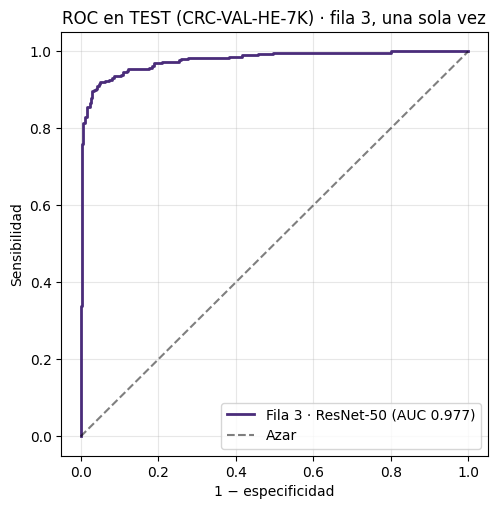

,Fila,Features,AUC test
0,1,Color (6),0.752
1,2,Color + textura (11),0.936
2,3,ResNet-50 ImageNet (2048),0.977


In [35]:
# §16 ⚠️ TEST: una sola vez para la fila 3
import warnings
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")
    m3 = nuevo_modelo().fit(X_tr, ytr_num)                     # entrenar SOLO con train
print("Avisos del ajuste:", [str(a.message)[:90] for a in avisos] or "ninguno")

p_f3 = m3.predict_proba(X_te)[:, 1]                             # P(TUM) por parche de test
auc_f3 = roc_auc_score(yte_num, p_f3)
tn, fp, fn, tp = confusion_matrix(yte_num, (p_f3 >= 0.5).astype(int)).ravel()
print(f"Fila 3 · AUC test {auc_f3:.3f} | sens@0.50 {tp / (tp + fn):.3f} | espec@0.50 {tn / (tn + fp):.3f}")
print("Referencia: fila 1 = 0.752 · fila 2 = 0.936")

np.savez(DOWNLOADS / "nct_probas_test_fila3.npz", p=p_f3, y=yte_num)   # para el Día 47

fpr, tpr, _ = roc_curve(yte_num, p_f3)
plt.figure(figsize=(5.5, 5.5))
plt.plot(fpr, tpr, lw=2, color="#4a2c7a", label=f"Fila 3 · ResNet-50 (AUC {auc_f3:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Azar")
plt.xlabel("1 − especificidad"); plt.ylabel("Sensibilidad")
plt.title("ROC en TEST (CRC-VAL-HE-7K) · fila 3, una sola vez")
plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.savefig(RESULTS / "07_roc_fila3.png", dpi=150, bbox_inches="tight"); plt.show()

import pandas as pd
pd.DataFrame({"Fila": [1, 2, 3],
              "Features": ["Color (6)", "Color + textura (11)", "ResNet-50 ImageNet (2048)"],
              "AUC test": [0.752, 0.936, round(auc_f3, 3)]})

### **§17 Variante: ¿importaba la decisión del Día 42?**

---



Qué hace: un solo cambio. Extrae los 1200 parches de train con el preprocesamiento de timm (Resize 235 + CenterCrop 224) y repite la misma CV. También mide cuánto se mueve cada vector. El test no se toca.
Mi predicción: diferencia de AUC CV ______ 0.01 · coseno medio ______ 0.95
Puente: cambiar solo el tiempo de recuperación antigénica en la serie interna, nunca en la de validación.

In [36]:
# §17 Variante en train: prep_timm vs prep_mano (mismo modelo, misma CV)
t0 = time.perf_counter()
X_tr_timm = extraer(modelo, Xtr, prep_timm)
print(f"Extracción con timm: {time.perf_counter() - t0:.0f} s")

for nombre, X in [("a mano (sin Resize/Crop)", X_tr),
                  ("timm (Resize 235 + Crop 224)", X_tr_timm)]:
    s = cross_val_score(nuevo_modelo(), X, ytr_num, cv=cv, scoring="roc_auc")
    print(f"{nombre:<30} AUC CV 5f {s.mean():.3f} ± {s.std():.3f}")

c = coseno_por_fila(X_tr, X_tr_timm)
print(f"Coseno a mano vs timm (1200 parches) · media {c.mean():.3f} | mínimo {c.min():.3f}")

Extracción con timm: 8 s
a mano (sin Resize/Crop)       AUC CV 5f 0.990 ± 0.004
timm (Resize 235 + Crop 224)   AUC CV 5f 0.989 ± 0.005
Coseno a mano vs timm (1200 parches) · media 0.946 | mínimo 0.872


### **E1 ⭐ Tipos de variables y unidad de análisis**

---

Qué hace: arma una tabla con cada variable que usas: tipo y nivel (paciente, laminilla, parche, análisis). Llénala tú; la celda solo te da el esqueleto.
Puente: paciente → bloque → laminilla → campo.

In [ ]:
import pandas as pd

filas = [
    # variable            tipo                    nivel        nota
    ("slide_id",          "categórica nominal",   "laminilla", "identifica la laminilla (CMU-1)"),
    ("pct_tejido",        "numérica continua",    "parche",    "fracción 0–1 de tejido en el tile"),
    ("x",                 "discreta",             "parche",    "ancho del tile"),
    ("y",                 "discreta",             "parche",    "alto del tile"),
    ("nivel",             "discreta",             "parche",    "nivel de la piramide de WSI en que trabaja el parche"),
    ("w",                 "discrteta",            "parche",    "nivel en x donde se inicia el corte"),
    ("h",                 "discreta",             "parche",    "nivel en y donde inicia el corte"),
    ("MPP",               "continua",             "laminilla", "micras por pixel"),
    ("fuente",            "nominal",              "laminilla", "recurso donde se extrajo el WSI"),
    ("semilla",           "discreta",             "analisis",  "semilla asignada para reproducibilidad"),
    ("ytr (npz)",         "nominal",              "parche",    "¿a qué nivel se asignó REALMENTE? (TUM/NORM)"),
    ("embedding (2048)",  "continua?",            "parche",    "2048 variables (una por filtro)"),
    ("patient_id",        "nominal",              "paciente",  "NO existe en NCT-CRC por parche"),
]
e1 = pd.DataFrame(filas, columns=["variable", "tipo", "nivel", "nota"])
e1

### **E10 ⭐ La misma prueba, otra población**

Qué hace: con la sensibilidad y la especificidad fijas de tu baseline de color, calcula el VPP y el VPN a distintas prevalencias, las razones de verosimilitud y el VPP al 10 % por la ruta de las odds.
Puente: IHQ de MMR en cribado universal vs en una consulta de alto riesgo.

In [ ]:
tn, fp, fn, tp = 227, 73, 94, 206               # tu matriz [[227, 73], [94, 206]]
sens = tp / (tp + fn)
espec = tn / (tn + fp)
print(f"Sensibilidad {sens:.3f} | especificidad {espec:.3f} | prevalencia del test {(tp + fn) / 600:.0%}")

def vpp(p):
    return sens * p / (sens * p + (1 - espec) * (1 - p))

def vpn(p):
    return espec * (1 - p) / (espec * (1 - p) + (1 - sens) * p)

for p in [0.50, 0.15, 0.10, 0.02]:
    print(f"Prevalencia {p:>4.0%} → VPP {vpp(p):.3f} | VPN {vpn(p):.3f}")

lr_pos = sens / (1 - espec)
lr_neg = (1 - sens) / espec
print(f"LR+ {lr_pos:.2f} | LR− {lr_neg:.2f}")

# Ruta de las odds: odds previas × LR+ = odds posteriores → probabilidad
p = 0.10
odds_post = p / (1 - p) * lr_pos
print(f"VPP al 10 % por odds: {odds_post / (1 + odds_post):.3f}")